# Visa/Mastercard Equity Research Valuation Python Program
Values Visa and Mastercard as of November 6, 2026, using free public data from Yahoo Finance and FRED.
Run `python fetch_data.py` first, then choose **Run All**. The five report charts get saved to the `charts` folder.

## Libraries

In [57]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

BLUE = "#2F6FDB"
ORANGE = "#C2611B"
NAVY = "#14213D"

plt.rcParams["text.parse_math"] = False
os.makedirs("charts", exist_ok=True)

## Step 1: Inputs
Pulls in everything `fetch_data.py` saved, like price, shares, cash flow and debt, and puts each company's numbers in its own labeled box. Every step below reads from these two boxes.

In [58]:
inputs = pd.read_csv("data/inputs.csv", index_col="field")

fields = ["price", "shares", "fcf0", "net_debt", "eps_this", "eps_next", "eps_two_out",
          "ebitda", "street_target", "low_52w", "high_52w"]
visa = {}
mastercard = {}
for f in fields:
    visa[f] = float(inputs.loc[f, "V"])          # each CSV column becomes one company's box
    mastercard[f] = float(inputs.loc[f, "MA"])

risk_free = float(inputs.loc["risk_free_rate", "V"])

print("Visa EPS years:      ", inputs.loc["eps_years", "V"])
print("Mastercard EPS years:", inputs.loc["eps_years", "MA"])
pd.DataFrame({"Visa": visa, "Mastercard": mastercard}).round(2)

Visa EPS years:       fiscal 2026 actual / fiscal 2027 / fiscal 2028
Mastercard EPS years: 2026 / 2027 / 2028 (extended at 2027 growth)


,Visa,Mastercard
price,422.65,652.70
shares,1865.80,871.18
fcf0,22057.00,15430.00
net_debt,7988.00,13474.00
eps_this,13.27,20.06
eps_next,15.03,23.16
eps_two_out,17.13,26.75
ebitda,31277.00,23326.00
street_target,453.22,720.69
low_52w,295.52,471.55


## Step 2: Assumptions
The three numbers that are my judgment instead of data: how fast cash flow grows, the extra return stocks are supposed to pay, and growth after year 10. Change one and everything below moves.

In [59]:
risk_premium = 0.0423
long_term_growth = 0.03

visa["growth"] = 0.11
mastercard["growth"] = 0.13

print(f"Risk-free rate: {risk_free:.2%}")
print(f"Risk premium:   {risk_premium:.2%}")

Risk-free rate: 4.86%
Risk premium:   4.23%


## Step 3: Beta
Measures how jumpy each stock is compared to the S&P 500, using two years of weekly returns. Under 1 means calmer than the market.

In [60]:
prices = pd.read_csv("data/prices.csv", index_col="date", parse_dates=True)

last_two_years = prices[prices.index >= prices.index[-1] - pd.DateOffset(years=2)]
weekly_prices = last_two_years.resample("W-FRI").last()     # keeps one closing price per week (Friday)
weekly_returns = weekly_prices.pct_change().dropna()         # turns prices into % changes, week to week

market = weekly_returns["SPX"]
for name, c, ticker in [("Visa", visa, "V"), ("Mastercard", mastercard, "MA")]:
    stock = weekly_returns[ticker]
    raw_beta = stock.cov(market) / market.var()   # how much the stock moves with the market, scaled so the market = 1
    c["beta"] = 0.67 * raw_beta + 0.33             # pulled toward 1, like Bloomberg, since betas drift toward 1 over time
    print(f"{name}: raw beta {raw_beta:.3f}, adjusted beta {c['beta']:.3f}")

Visa: raw beta 0.699, adjusted beta 0.798
Mastercard: raw beta 0.731, adjusted beta 0.820


## Step 4: Discount rate
This is the yearly return an investor should want for owning the stock. You start with the 10-year Treasury rate, since that's what you'd get risk-free, then add extra for how jumpy the stock is: beta times the market's risk premium. The higher this number, the less future cash is worth today, so it pulls the DCF value down.

In [61]:
for name, c in [("Visa", visa), ("Mastercard", mastercard)]:
    c["r"] = risk_free + c["beta"] * risk_premium
    print(f"{name}: {risk_free:.2%} + {c['beta']:.3f} x {risk_premium:.2%} = {c['r']:.2%}")

Visa: 4.86% + 0.798 x 4.23% = 8.24%
Mastercard: 4.86% + 0.820 x 4.23% = 8.33%


## Step 5: DCF
Grows the cash flow out ten years, then shrinks each year back to today's dollars. Subtract debt, divide by shares, and that's what one share is worth.

In [62]:
def dcf_parts(c, growth, r, ltg):
    cash = c["fcf0"]
    years_1_10 = 0

    for year in range(1, 11):
        if year <= 5:
            g = growth
        else:
            g = growth - (growth - ltg) * (year - 5) / 5   # years 6-10: growth fades evenly down to long-term growth

        cash = cash * (1 + g)
        years_1_10 += cash / (1 + r) ** year         # shrink this year's cash back to today's dollars

    terminal = cash * (1 + ltg) / (r - ltg)          # every year after 10, valued all at once (as of year 10)
    after_10 = terminal / (1 + r) ** 10              # then shrunk back 10 years to today
    return years_1_10, after_10


def dcf_per_share(c, growth, r, ltg):
    years_1_10, after_10 = dcf_parts(c, growth, r, ltg)
    equity = years_1_10 + after_10 - c["net_debt"]   # lenders get paid first, so their claim comes off the top
    return equity / c["shares"]


for name, c in [("Visa", visa), ("Mastercard", mastercard)]:
    c["dcf"] = dcf_per_share(c, c["growth"], c["r"], long_term_growth)
    years_1_10, after_10 = dcf_parts(c, c["growth"], c["r"], long_term_growth)
    share_after_10 = after_10 / (years_1_10 + after_10)
    print(f"{name}: DCF value ${c['dcf']:.0f} per share ({share_after_10:.0%} of the value comes after year 10)")

Visa: DCF value $364 per share (65% of the value comes after year 10)
Mastercard: DCF value $592 per share (65% of the value comes after year 10)


## Step 6: P/E and target
Assumes investors keep paying today's price-to-earnings multiple next year. Averaging that with the DCF gives the 12-month target.

In [63]:
for name, c in [("Visa", visa), ("Mastercard", mastercard)]:
    c["pe"] = c["price"] / c["eps_next"]
    c["pe_value"] = c["pe"] * c["eps_two_out"]      # same multiple, applied to earnings a year further out
    c["target"] = (c["dcf"] + c["pe_value"]) / 2
    change = c["target"] / c["price"] - 1
    print(f"{name}: P/E {c['pe']:.2f}x | DCF ${c['dcf']:.0f} | P/E value ${c['pe_value']:.0f} | "
          f"target ${c['target']:.0f} ({change:+.1%} vs. ${c['price']:.2f}) | Street ${c['street_target']:.0f}")

Visa: P/E 28.11x | DCF $364 | P/E value $482 | target $423 (+0.1% vs. $422.65) | Street $453
Mastercard: P/E 28.18x | DCF $592 | P/E value $754 | target $673 (+3.1% vs. $652.70) | Street $721


## Step 7: Price checks
Three quick rules of thumb, to see if the target makes sense.

In [64]:
for name, c in [("Visa", visa), ("Mastercard", mastercard)]:
    eps_growth = c["eps_next"] / c["eps_this"] - 1
    pe_to_growth = c["pe"] / (eps_growth * 100)    # growth as a whole number (13.3, not 0.133), the usual way it's quoted
    market_value = c["price"] * c["shares"]
    fcf_yield = c["fcf0"] / market_value
    enterprise_value = market_value + c["net_debt"]
    ev_to_ebitda = enterprise_value / c["ebitda"]
    print(f"{name}: EPS growth {eps_growth:.1%} | P/E / growth {pe_to_growth:.1f}x | "
          f"FCF yield {fcf_yield:.1%} | EV ${enterprise_value/1000:.1f}B | EV/EBITDA {ev_to_ebitda:.1f}x")

Visa: EPS growth 13.3% | P/E / growth 2.1x | FCF yield 2.8% | EV $796.6B | EV/EBITDA 25.5x
Mastercard: EPS growth 15.5% | P/E / growth 1.8x | FCF yield 2.7% | EV $582.1B | EV/EBITDA 25.0x


## Step 8: Reverse DCF
Runs the DCF backwards to find what the market is assuming at today's price.

In [65]:
for name, c in [("Visa", visa), ("Mastercard", mastercard)]:
    best_rate = 0
    smallest_gap = 999999
    for step in range(401):                         # tries every rate from 6.00% to 10.00%, 0.01% apart
        rate = 0.06 + step / 10000
        value = dcf_per_share(c, c["growth"], rate, long_term_growth)
        gap = abs(value - c["price"])
        if gap < smallest_gap:                      # keeps whichever rate lands closest to today's price
            smallest_gap = gap
            best_rate = rate
    c["implied_rate"] = best_rate
    print(f"{name}: today's price implies a {best_rate:.2%} discount rate (ours: {c['r']:.2%})")

Visa: today's price implies a 7.56% discount rate (ours: 8.24%)
Mastercard: today's price implies a 7.87% discount rate (ours: 8.33%)


## Step 9: Sensitivity
Reruns the DCF 15 times to show how much it moves if my two biggest guesses are off.

In [66]:
rate_changes = [-0.01, -0.005, 0, 0.005, 0.01]
growth_options = [0.025, 0.03, 0.035]

for name, c in [("Visa", visa), ("Mastercard", mastercard)]:
    table = []
    for change in rate_changes:                     # outer loop: one row per discount rate
        row = []
        for ltg in growth_options:                  # inner loop: one column per long-term growth rate
            row.append(dcf_per_share(c, c["growth"], c["r"] + change, ltg))
        table.append(row)

    row_names = ["-1 point", "-0.5 point", "Base", "+0.5 point", "+1 point"]
    print(name)
    display(pd.DataFrame(table, index=row_names, columns=["growth 2.5%", "growth 3.0%", "growth 3.5%"]).round(0))

Visa


,growth 2.5%,growth 3.0%,growth 3.5%
-1 point,416.0,457.0,508.0
-0.5 point,374.0,406.0,445.0
Base,339.0,364.0,395.0
+0.5 point,310.0,330.0,355.0
+1 point,285.0,302.0,322.0


Mastercard


,growth 2.5%,growth 3.0%,growth 3.5%
-1 point,677.0,742.0,825.0
-0.5 point,607.0,659.0,723.0
Base,550.0,592.0,642.0
+0.5 point,502.0,536.0,576.0
+1 point,461.0,489.0,522.0


## Step 10: Bear, base and bull
Reruns both methods with worse and better assumptions. Weighting them 25, 50, 25 gives one blended value.

In [67]:
for name, c in [("Visa", visa), ("Mastercard", mastercard)]:
    bear_dcf = dcf_per_share(c, c["growth"] - 0.02, c["r"] + 0.005, long_term_growth)
    bull_dcf = dcf_per_share(c, c["growth"] + 0.02, c["r"] - 0.005, long_term_growth)
    bear_pe = c["pe"] * 0.9 * c["eps_two_out"] * 0.95
    bull_pe = c["pe"] * 1.1 * c["eps_two_out"] * 1.05

    c["bear"] = (bear_dcf + bear_pe) / 2
    c["bull"] = (bull_dcf + bull_pe) / 2
    c["weighted"] = 0.25 * c["bear"] + 0.5 * c["target"] + 0.25 * c["bull"]
    print(f"{name}: bear ${c['bear']:.0f} | base ${c['target']:.0f} | bull ${c['bull']:.0f} | "
          f"weighted ${c['weighted']:.0f}")

Visa: bear $353 | base $423 | bull $506 | weighted $426
Mastercard: bear $561 | base $673 | bull $805 | weighted $678


## Step 11: Monte Carlo
Runs the DCF 20,000 times with random assumptions and counts how often it beats today's price. The seed is fixed, so you get the same answer every time.

In [68]:
rng = np.random.default_rng(42)                     # fixed seed: same "random" numbers every run
runs = 20000

for name, c in [("Visa", visa), ("Mastercard", mastercard)]:
    growths = rng.normal(c["growth"], 0.02, runs)    # bell curve: most guesses land near ours
    rates = rng.normal(c["r"], 0.005, runs)
    ltgs = rng.uniform(0.025, 0.035, runs)           # even spread: anything from 2.5% to 3.5% is equally likely

    values = []
    for i in range(runs):
        values.append(dcf_per_share(c, growths[i], rates[i], ltgs[i]))
    c["mc"] = np.array(values)

    low = np.percentile(c["mc"], 5)
    high = np.percentile(c["mc"], 95)
    above = np.mean(c["mc"] > c["price"])
    print(f"{name}: middle 90% of runs ${low:.0f} to ${high:.0f}; {above:.0%} of runs above today's price")

Visa: middle 90% of runs $283 to $481; 18% of runs above today's price
Mastercard: middle 90% of runs $460 to $783; 27% of runs above today's price


# Charts
The report's five charts, drawn exactly as they appear in the report (same sizes, fonts and colors).
Each one is saved as a PNG in the `charts` folder, named after its exhibit number in the report.

###### (the code for displaying charts were made with the help of LLMs.)

In [69]:
# One shared look for every chart: Arial (or the closest font installed), small text, no top/right borders
GRAY = "#5B6475"     # labels
GRID = "#E3E6EC"     # light grid lines
plt.rcParams.update({
    "font.family": ["Arial", "Liberation Sans", "DejaVu Sans"],   # first one installed is used
    "font.size": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#9AA1AE",
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "text.color": NAVY,
    "axes.labelcolor": NAVY,
})

def save(fig, filename):
    """Save a chart at print quality (300 dots per inch) into the charts folder, then show it."""
    fig.savefig("charts/" + filename, dpi=300, facecolor=fig.get_facecolor(), bbox_inches="tight", pad_inches=0.04)
    plt.show()

## Exhibit 1: Growth of $100 over 3 years (dividends reinvested)

In [70]:
# Yahoo adjusted closes (dividends reinvested) and the S&P 500 total return index
returns = prices[["V_TR", "MA_TR", "SPX_TR"]]
returns.columns = ["Visa", "Mastercard", "S&P 500"]

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

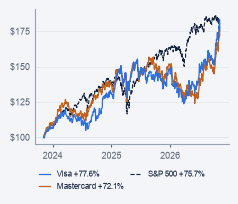

In [71]:
growth_of_100 = returns / returns.iloc[0] * 100      # every line starts at $100

fig, ax = plt.subplots(figsize=(2.5, 1.75))          # small: it sits in the page 1 sidebar
fig.patch.set_facecolor("#F3F5F8")                   # same light gray as the sidebar
ax.set_facecolor("#F3F5F8")
for name, color, style in [("S&P 500", NAVY, "--"), ("Mastercard", ORANGE, "-"), ("Visa", BLUE, "-")]:
    total = growth_of_100[name].iloc[-1] - 100
    ax.plot(growth_of_100.index, growth_of_100[name], style, color=color, linewidth=0.8 if name == "S&P 500" else 0.9, label=f"{name} +{total:.1f}%")

ax.axhline(100, color=GRID, linewidth=0.6, zorder=0)          # starting line
ax.set_yticks([100, 125, 150, 175], ["$100", "$125", "$150", "$175"], fontsize=6.5)
ax.xaxis.set_major_locator(mdates.YearLocator())          # one tick per year
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.tick_params(axis="x", labelsize=6.5, length=2)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", color=GRID, linewidth=0.5)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper center", bbox_to_anchor=(0.45, -0.14), ncol=2, frameon=False, fontsize=6, handlelength=1.3, columnspacing=0.8)
save(fig, "exhibit01_growth_of_100.png")

## Exhibit 4: Where gross revenue comes from (before payments to banks)
Visa: fiscal 2026 annual report. Mastercard: Q3 2026 earnings presentation. $ millions.

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

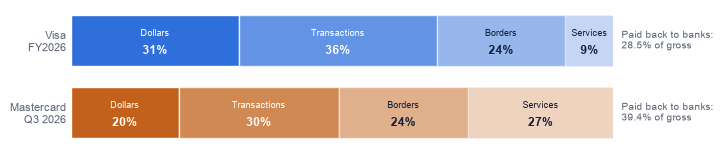

In [72]:
categories = ["Dollars", "Transactions", "Borders", "Services"]
companies = [
    ("Visa\nFY2026",       [19918, 23374, 15251, 5677],     18317, BLUE),    # name, revenue by category, paid to banks
    ("Mastercard\nQ3 2026", [3211, 4781, 3841, 285 + 4058], 6369,  ORANGE),
]
shades = [1, 0.75, 0.5, 0.28]                         # darkest to lightest

fig, ax = plt.subplots(figsize=(7.0, 1.75))
for row, (name, revenue, paid_to_banks, color) in enumerate(companies):
    gross = sum(revenue)
    left = 0
    for i in range(len(categories)):
        pct = revenue[i] / gross * 100
        ax.barh(row, pct, left=left, height=0.7, color=color, alpha=shades[i], edgecolor="white")
        text_color = "white" if i < 2 else NAVY     # white text on the dark segments
        ax.text(left + pct / 2, row - 0.1, categories[i], ha="center", va="center", fontsize=6.5, color=text_color)
        ax.text(left + pct / 2, row + 0.14, f"{pct:.0f}%", ha="center", va="center", fontsize=8.5, fontweight="bold", color=text_color)
        left += pct
    ax.text(101.5, row, f"Paid back to banks:\n{paid_to_banks / gross:.1%} of gross", va="center", fontsize=7, color=GRAY)

ax.set_yticks([0, 1], [c[0] for c in companies], fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
save(fig, "exhibit04_revenue_mix.png")

## Exhibit 15: Monte Carlo results

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

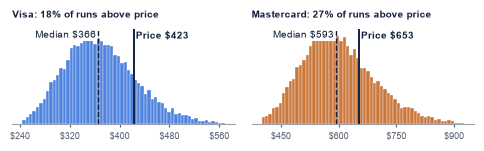

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(4.9, 1.55))
label_box = dict(boxstyle="square,pad=0.12", facecolor="white", edgecolor="none")   # white tag behind text

for ax, name, c, color in [(axes[0], "Visa", visa, BLUE), (axes[1], "Mastercard", mastercard, ORANGE)]:
    low, high = np.percentile(c["mc"], [0.5, 99.5])   # trim the extreme 1% so the bars are readable
    ax.hist(c["mc"], bins=60, range=(low, high), color=color, alpha=0.85, edgecolor="white", linewidth=0.3)
    middle = np.median(c["mc"])
    ax.axvline(c["price"], color=NAVY, linewidth=1.4)                 # solid line: today's price
    ax.axvline(middle, color=NAVY, linewidth=1, linestyle="--")       # dashed line: middle result
    top = ax.get_ylim()[1]
    ax.text(c["price"] + (high - low) * 0.01, top * 0.98, f"Price ${c['price']:.0f}", fontsize=7, va="top", fontweight="bold", bbox=label_box)
    ax.text(middle - (high - low) * 0.01, top * 0.98, f"Median ${middle:.0f}", fontsize=7, va="top", ha="right", bbox=label_box)
    above = np.mean(c["mc"] > c["price"])
    ax.set_title(f"{name}: {above:.0%} of runs above price", loc="left", fontsize=7.5, fontweight="bold", pad=8)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.tick_params(axis="x", labelsize=6.5, length=2)

fig.tight_layout(w_pad=1.5)
save(fig, "exhibit15_monte_carlo.png")

## Exhibit 16: Football field (every valuation range vs. price, our target and the Street)

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

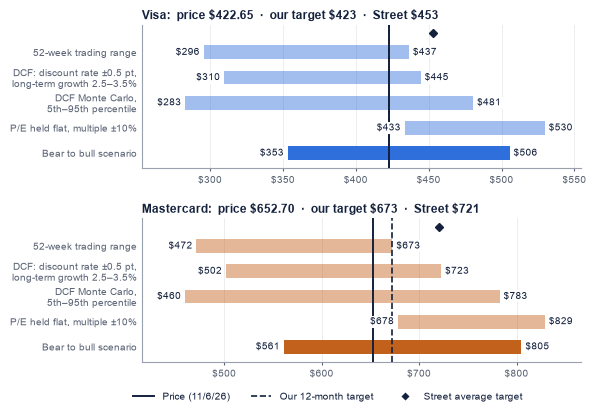

In [74]:
row_names = ["52-week trading range", "DCF: discount rate ±0.5 pt,\nlong-term growth 2.5–3.5%",
             "DCF Monte Carlo,\n5th–95th percentile", "P/E held flat, multiple ±10%", "Bear to bull scenario"]
label_box = dict(boxstyle="square,pad=0.15", facecolor="white", edgecolor="none")

fig, axes = plt.subplots(2, 1, figsize=(6.0, 4.1))
for ax, name, c, color in [(axes[0], "Visa", visa, BLUE), (axes[1], "Mastercard", mastercard, ORANGE)]:
    ranges = [
        (c["low_52w"], c["high_52w"]),
        (dcf_per_share(c, c["growth"], c["r"] + 0.005, 0.025), dcf_per_share(c, c["growth"], c["r"] - 0.005, 0.035)),
        (np.percentile(c["mc"], 5), np.percentile(c["mc"], 95)),
        (c["pe_value"] * 0.9, c["pe_value"] * 1.1),
        (c["bear"], c["bull"]),
    ]
    gap = c["high_52w"] * 0.006                       # small space between a bar and its label
    for i in range(len(ranges)):
        low, high = ranges[i]
        ax.barh(i, high - low, left=low, height=0.55, color=color, alpha=1 if i == 4 else 0.45)
        ax.text(low - gap, i, f"${low:.0f}", ha="right", va="center", fontsize=7, bbox=label_box, zorder=6)
        ax.text(high + gap, i, f"${high:.0f}", ha="left", va="center", fontsize=7, bbox=label_box, zorder=6)

    ax.axvline(c["price"], color=NAVY, linewidth=1.4, zorder=3)                      # today's price
    ax.axvline(c["target"], color=NAVY, linewidth=1.2, linestyle="--", zorder=3)     # our target
    ax.plot([c["street_target"]], [-0.75], marker="D", color=NAVY, markersize=4.5, clip_on=False)   # Street target

    ax.set_yticks(range(5), row_names, fontsize=7.2)
    ax.invert_yaxis()
    ax.tick_params(axis="y", length=0)
    every_value = [v for pair in ranges for v in pair] + [c["street_target"]]
    span = max(every_value) - min(every_value)
    ax.set_xlim(min(every_value) - span * 0.12, max(every_value) + span * 0.10)
    ax.set_ylim(4.6, -1.1)
    ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
    ax.tick_params(axis="x", labelsize=7, length=2)
    ax.grid(axis="x", color=GRID, linewidth=0.5)
    ax.set_axisbelow(True)
    ax.set_title(f"{name}:  price ${c['price']:.2f}  ·  our target ${c['target']:.0f}  ·  Street ${c['street_target']:.0f}",
                 loc="left", fontsize=8.5, fontweight="bold", pad=4)

legend_items = [Line2D([0], [0], color=NAVY, linewidth=1.4, label="Price (11/6/26)"),
                Line2D([0], [0], color=NAVY, linewidth=1.2, linestyle="--", label="Our 12-month target"),
                Line2D([0], [0], marker="D", color="white", markerfacecolor=NAVY, markersize=5, label="Street average target")]
fig.legend(handles=legend_items, loc="lower center", ncol=3, frameon=False, fontsize=7.5, bbox_to_anchor=(0.55, -0.01))
fig.tight_layout(rect=(0, 0.04, 1, 1), h_pad=1.6)
save(fig, "exhibit16_football_field.png")

## Exhibit 18: Risk matrix (our judgment)

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

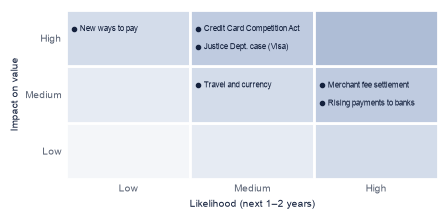

In [75]:
# (risk, likelihood, impact, position inside its box) with 0 = low, 1 = medium, 2 = high
risks = [
    ("Credit Card Competition Act", 1, 2, 0),
    ("Justice Dept. case (Visa)",   1, 2, 1),
    ("New ways to pay",             0, 2, 0),
    ("Travel and currency",         1, 1, 0),
    ("Merchant fee settlement",     2, 1, 0),
    ("Rising payments to banks",    2, 1, 1),
]
shades = ["#F4F6F9", "#E6EBF3", "#D3DCEA", "#BFCBE0", "#AEBDD6"]   # lighter = less serious

fig, ax = plt.subplots(figsize=(4.8, 2.2))
for x in range(3):
    for y in range(3):
        ax.add_patch(plt.Rectangle((x, y), 1, 1, facecolor=shades[x + y], edgecolor="white", linewidth=2))

for name, likelihood, impact, slot in risks:
    y = impact + 0.66 - slot * 0.32          # second risk in a box goes a little lower
    ax.plot(likelihood + 0.06, y, "o", color=NAVY, markersize=3)
    ax.text(likelihood + 0.11, y, name, va="center", fontsize=6.1)

ax.set_xlim(0, 3)
ax.set_ylim(0, 3)
ax.set_xticks([0.5, 1.5, 2.5], ["Low", "Medium", "High"])
ax.set_yticks([0.5, 1.5, 2.5], ["Low", "Medium", "High"])
ax.tick_params(length=0, labelsize=7.5)
ax.set_xlabel("Likelihood (next 1–2 years)", fontsize=7.5)
ax.set_ylabel("Impact on value", fontsize=7.5)
for side in ax.spines.values():
    side.set_visible(False)
save(fig, "exhibit18_risk_matrix.png")

## Summary

In [76]:
summary = {}
for name, c in [("Visa", visa), ("Mastercard", mastercard)]:
    summary[name] = {
        "price": round(c["price"], 2),
        "discount rate": round(c["r"], 4),
        "DCF value": round(c["dcf"]),
        "P/E value": round(c["pe_value"]),
        "target": round(c["target"]),
        "bear": round(c["bear"]),
        "bull": round(c["bull"]),
        "weighted": round(c["weighted"]),
        "implied rate": round(c["implied_rate"], 4),
        "share of runs above price": round(float(np.mean(c["mc"] > c["price"])), 2),
    }
pd.DataFrame(summary)

,Visa,Mastercard
price,422.6500,652.7000
discount rate,0.0824,0.0833
DCF value,364.0000,592.0000
P/E value,482.0000,754.0000
target,423.0000,673.0000
bear,353.0000,561.0000
bull,506.0000,805.0000
weighted,426.0000,678.0000
implied rate,0.0756,0.0787
share of runs above price,0.1800,0.2700
